# Mecânica dos Fluidos — Projeto 1
## Escoamento de Hagen–Poiseuille: da modelagem física à solução pelo Método dos Elementos Finitos

**Prazo:** 3 semanas  
**Entrega:** artigo em PDF + notebook Jupyter (`.ipynb`) executável

### Objetivo
Estudar o escoamento laminar em um tubo cilíndrico, partindo da dedução física [Nussenzveig, 2004] e desenvolvendo a formulação variacional, a solução pelo MEF/FEniCSx e sua verificação.

$$
\boxed{\text{problema físico}\to\text{modelo}\to\text{solução analítica}\to\text{forma fraca}\to\text{MEF}\to\text{FEniCSx}\to\text{verificação}}
$$

Este notebook é um **roteiro**, não uma solução pronta. As células incompletas deverão ser desenvolvidas pelo grupo.

## 1. Referência básica

**NUSSENZVEIG, H. M.** *Curso de Física Básica: Fluidos, Oscilações e Ondas, Calor*. v. 2. 4. ed. São Paulo: Edgard Blücher, 2002. Reimpressão, 2004.

Consultar a seção sobre viscosidade, particularmente a dedução da **lei de Hagen–Poiseuille**.

O grupo deverá citar a fonte e apresentar a dedução com suas próprias explicações.

## 2. Problema físico

Considere um tubo de raio $a$ e comprimento $l$, contendo um fluido newtoniano de viscosidade $\eta$, submetido a pressões $p_1>p_2$.

Admite-se escoamento estacionário, incompressível, laminar, axisimétrico e plenamente desenvolvido:

$$v=v(r).$$

Na parede:
$$\boxed{v(a)=0}.$$

No eixo, por simetria:
$$\boxed{\left.\frac{dv}{dr}\right|_{r=0}=0}.$$

### Para pensar — Respostas e discussão

1. **Por que $v$ depende apenas de $r$?**  
   Pelos mesmos argumentos físicos discutidos na **Aula 1 (Seção 5.1)**: como o escoamento é **estacionário**, não depende do tempo ($t$); como é **axisimétrico**, não varia com o ângulo azimutal ($\theta$); e como é **plenamente desenvolvido** e incompressível, o perfil de velocidade não se altera ao longo do comprimento axial ($z$). Logo, a velocidade axial depende exclusivamente da distância radial ao centro do tubo: $v = v(r)$.

2. **Por que $v(a)=0$?**  
   Pela **condição de não deslizamento** (*no-slip condition*), estudada na **Aula 1 (Seção 5.5)**: um fluido viscoso em contato com uma parede sólida impermeável adere a ela e assume a mesma velocidade da parede. Como o tubo está em repouso em $r = a$, temos obrigatoriamente $v(a) = 0$.

3. **Por que não devemos impor $v(0)=0$?**  
   Porque $r = 0$ não é uma parede sólida, mas sim o **eixo central de simetria** do tubo, onde o fluido flui livremente longe do atrito direto das paredes. Impor $v(0) = 0$ significaria, fisicamente, introduzir um fio sólido estacionário no centro do tubo, alterando completamente o problema físico. No centro, a condição correta é de simetria: $\left.\frac{dv}{dr}\right|_{r=0} = 0$.

4. **Onde se espera a velocidade máxima?**  
   No eixo central do tubo ($r = 0$), pois é a região mais distante das paredes estacionárias ($r = a$) onde atua a resistência viscosa, e onde a derivada radial $\frac{dv}{dr}$ se anula (ponto de máximo da parábola).

## 3. Dedução física — ponto de partida

Seguindo Nussenzveig [2004], considere um cilindro coaxial de fluido de raio $r$ e comprimento $l$.

$$F_p=(p_1-p_2)\pi r^2,$$

enquanto a área lateral é

$$A=2\pi r l.$$

Assim,

$$\frac{F}{A}=\frac{p_1-p_2}{2l}r.$$

Pela lei de Newton da viscosidade,

$$\frac{F}{A}=-\eta\frac{dv}{dr},$$

logo

$$\boxed{\frac{dv}{dr}=-\frac{p_1-p_2}{2l\eta}r}.$$

### Tarefa — Integração e obtenção do perfil parabólico

Definindo o gradiente hidráulico de pressão $G = \frac{p_1 - p_2}{l}$, reescrevemos a equação diferencial de 1ª ordem como:

$$\frac{dv}{dr} = -\frac{G}{2\eta}r.$$

Integrando ambos os lados em relação a $r$:

$$v(r) = \int \left(-\frac{G}{2\eta}r\right) dr = -\frac{G}{2\eta}\frac{r^2}{2} + C = -\frac{G}{4\eta}r^2 + C,$$

onde $C$ é a constante de integração. Aplicando a condição de contorno de não deslizamento na parede ($v(a) = 0$):

$$v(a) = -\frac{G}{4\eta}a^2 + C = 0 \implies C = \frac{G}{4\eta}a^2.$$

Substituindo a constante $C$ na expressão de $v(r)$, obtemos o **perfil parabólico de Hagen–Poiseuille**:

$$\boxed{v(r) = \frac{G}{4\eta}(a^2 - r^2) = \frac{p_1 - p_2}{4l\eta}(a^2 - r^2)}.$$

## 4. Solução analítica para verificação

Defina

$$G=\frac{p_1-p_2}{l}.$$

A solução analítica é

$$\boxed{v_{\rm exato}(r)=\frac{G}{4\eta}(a^2-r^2)}.$$

A vazão é

$$\boxed{Q_{\rm exato}=\frac{\pi a^4G}{8\eta}}.$$

A solução analítica será utilizada para **verificar** a implementação numérica.

## 5. Da equação diferencial à forma fraca

Uma forma conveniente da equação é

$$-\frac{1}{r}\frac{d}{dr}\left(\eta r\frac{dv}{dr}\right)=G.$$

Multiplicando por $r$:

$$-\frac{d}{dr}\left(\eta r\frac{dv}{dr}\right)=Gr.$$

### Tarefa de formulação — Passo a passo da Forma Fraca

Utilizando uma função teste $w(r)$ e seguindo o procedimento da **Aula 3 (Seção 2)**:

1. **Passos da dedução (multiplicação por $w$ e integração por partes):**  
   Multiplicamos a equação diferencial por $w(r)$ e integramos em $r \in [0, a]$:
   $$-\int_0^a \frac{d}{dr}\left(\eta r \frac{dv}{dr}\right) w(r)\,dr = \int_0^a G r\,w(r)\,dr.$$
   Integrando o lado esquerdo por partes:
   $$-\left[\eta r \frac{dv}{dr} w(r)\right]_0^a + \int_0^a \eta r \frac{dv}{dr}\frac{dw}{dr}\,dr = \int_0^a G r\,w(r)\,dr.$$

2. **Discussão do termo de fronteira:**  
   Expandindo $-\left[\eta r v'(r) w(r)\right]_0^a = -\eta a v'(a) w(a) + \eta \cdot 0 \cdot v'(0) w(0)$:
   - Em $r = a$: como $v(a) = 0$ é condição de Dirichlet, a função teste satisfaz $w(a) = 0$, anulando a contribuição em $r = a$.
   - Em $r = 0$: o termo se anula tanto pelo fator geométrico $r = 0$ quanto pela condição física de simetria $v'(0) = 0$.

3. **Condição de simetria em $r=0$:**  
   Como o termo de fronteira em $r = 0$ desaparece naturalmente na integração por partes sem exigir $w(0) = 0$, a condição $\left.\frac{dv}{dr}\right|_{r=0} = 0$ é uma **condição de contorno natural (Neumann homogênea)**, sendo satisfeita automaticamente pela forma variacional.

4. **Origem do fator $r$:**  
   Vem do elemento diferencial de área em coordenadas cilíndricas, $dA = 2\pi r\,dr$ (jacobiano radial $r$), que pondera cada posição radial pela circunferência do anel correspondente.

Obtemos assim:

$$\boxed{\int_0^a\eta r\,v'w'\,dr=\int_0^a Gr\,w\,dr}.$$

## 6. Ambiente computacional

Recomenda-se **VS Code + Jupyter**, no ambiente FEniCSx utilizado nas aulas.

O notebook deve ser reprodutível: depois de reiniciar o kernel, **Run All** deverá reproduzir os resultados sem depender de execuções anteriores.

In [13]:
# ============================================================
# Importações básicas (mesmo padrão da Aula 3)
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt

from mpi4py import MPI
from petsc4py import PETSc
import dolfinx
from dolfinx import mesh, fem
from dolfinx.fem.petsc import LinearProblem
import ufl

# Cria uma pasta para salvar os gráficos para o artigo SBC
os.makedirs("figuras", exist_ok=True)

print("NumPy:", np.__version__)
print("DOLFINx:", dolfinx.__version__)
print("petsc4py:", PETSc.Sys.getVersion())
print("\nAmbiente carregado com sucesso!")

NumPy: 1.26.4
DOLFINx: 0.11.0.post0
petsc4py: (3, 19, 6)

Ambiente carregado com sucesso!


## 7. Parâmetros físicos

Escolha valores coerentes para $a$, $l$, $\eta$, $p_1$ e $p_2$, registre as unidades no Sistema Internacional (SI) e calcule

$$G=\frac{p_1-p_2}{l}.$$

Seguindo a abordagem didática da **Aula 1 (Seção 6)**, escolhemos valores unitários/simples no SI ($a = 1{,}0\text{ m}$, $l = 1{,}0\text{ m}$, $\eta = 1{,}0\text{ Pa}\cdot\text{s}$, $p_1 = 4{,}0\text{ Pa}$, $p_2 = 0{,}0\text{ Pa}$), pois isso resulta em $G = 4{,}0\text{ Pa/m}$ e torna o perfil analítico igual a $v_{\rm exato}(r) = 1 - r^2\text{ m/s}$, facilitando a verificação direta dos cálculos.

In [14]:
# ============================================================
# Definição dos parâmetros físicos no Sistema Internacional (SI)
# ============================================================
a = 1.0        # Raio interno do tubo [m]
l = 1.0        # Comprimento do tubo [m]
eta_val = 1.0  # Viscosidade dinâmica do fluido [Pa.s]
p1 = 4.0       # Pressão na entrada do tubo [Pa]
p2 = 0.0       # Pressão na saída do tubo [Pa]

# Cálculo do gradiente de pressão G = (p1 - p2) / l [Pa/m]
G_val = (p1 - p2) / l

# Velocidade máxima teórica no centro (r = 0) e vazão exata para referência
v_max_exato = (G_val / (4.0 * eta_val)) * (a ** 2)
Q_exato_ref = (np.pi * (a ** 4) * G_val) / (8.0 * eta_val)

print(f"Raio do tubo (a)          = {a:.2f} m")
print(f"Comprimento do tubo (l)   = {l:.2f} m")
print(f"Viscosidade (eta)         = {eta_val:.2f} Pa.s")
print(f"Diferença de pressão      = {p1 - p2:.2f} Pa")
print(f"Gradiente de pressão (G)  = {G_val:.2f} Pa/m")
print(f"Velocidade máxima (r = 0) = {v_max_exato:.4f} m/s")
print(f"Vazão analítica (Q_exato) = {Q_exato_ref:.6f} m^3/s")

Raio do tubo (a)          = 1.00 m
Comprimento do tubo (l)   = 1.00 m
Viscosidade (eta)         = 1.00 Pa.s
Diferença de pressão      = 4.00 Pa
Gradiente de pressão (G)  = 4.00 Pa/m
Velocidade máxima (r = 0) = 1.0000 m/s
Vazão analítica (Q_exato) = 1.570796 m^3/s


## 8. Malha radial

As hipóteses reduzem o problema ao intervalo

$$0\le r\le a.$$

Crie inicialmente uma malha com poucos elementos ($N = 4$) e examine suas coordenadas.

In [15]:
# ============================================================
# Criação da malha 1D no intervalo [0, a]
# ============================================================
N = 4  # Número inicial de elementos (subintervalos)

dominio = mesh.create_interval(
    MPI.COMM_WORLD,
    N,
    [0.0, a]
)

# Coordenadas dos nós da malha 1D
coordenadas_nos = dominio.geometry.x[:, 0]

print(f"Número de elementos (N) = {N}")
print(f"Tamanho do elemento (h) = {a / N:.4f} m")
print(f"Número de nós da malha  = {len(coordenadas_nos)}")
print("Coordenadas radiais r dos nós:", np.sort(coordenadas_nos))

Número de elementos (N) = 4
Tamanho do elemento (h) = 0.2500 m
Número de nós da malha  = 5
Coordenadas radiais r dos nós: [0.   0.25 0.5  0.75 1.  ]


## 9. Espaço de elementos finitos

Comece com elementos de Lagrange $P_1$.

Crie $V_h$, a função tentativa e a função teste.

### Para pensar — Resposta
**A solução parabólica de Hagen–Poiseuille pertence ao espaço $P_1$? Compare com o Couette estudado em aula.**
- **Não.** A solução exata de Hagen–Poiseuille é um polinômio de **2º grau** em $r$, $v(r) = \frac{G}{4\eta}(a^2 - r^2)$, enquanto o espaço de elementos finitos $P_1$ é formado por funções **lineares por partes** (polinômios de 1º grau em cada subintervalo). Por isso, uma malha com elementos $P_1$ apenas aproxima a parábola por uma linha poligonal (segmentos de reta), apresentando erro no interior dos elementos.
- No **escoamento de Couette simples** entre placas paralelas (sem gradiente de pressão, $G = 0$, apenas com uma placa móvel), o perfil de velocidade exato é uma **reta** (polinômio de 1º grau). Nesse caso, a solução exata pertence ao espaço $P_1$, e mesmo um único elemento linear já reproduz a solução exata sem erro de discretização.

In [16]:
# ============================================================
# Espaço de elementos finitos P1 (Lagrange de grau 1)
# ============================================================
V = fem.functionspace(dominio, ("Lagrange", 1))

# Função tentativa (incógnita v) e função teste (peso w)
v = ufl.TrialFunction(V)
w = ufl.TestFunction(V)

num_dofs = V.dofmap.index_map.size_global
print(f"Espaço P1 criado com {num_dofs} graus de liberdade (DOFs).")

Espaço P1 criado com 5 graus de liberdade (DOFs).


## 10. Coordenada radial e forma variacional

A coordenada $r$ aparece explicitamente:

$$a(v,w)=\int_0^a\eta r\,v'w'\,dr,$$

$$\ell(w)=\int_0^a Gr\,w\,dr.$$

Use `ufl.SpatialCoordinate` para representar a coordenada radial e implemente as duas formas em UFL.

In [17]:
# ============================================================
# Coordenada radial e formulação variacional em UFL
# ============================================================
x = ufl.SpatialCoordinate(dominio)
r = x[0]  # Em 1D, a única coordenada espacial x[0] representa o raio r

# Constantes físicas encapsuladas para o FEniCSx
eta = fem.Constant(dominio, PETSc.ScalarType(eta_val))
G = fem.Constant(dominio, PETSc.ScalarType(G_val))

# Forma bilinear a(v, w) = integral de eta * r * v' * w' dr
a_form = eta * r * ufl.inner(ufl.grad(v), ufl.grad(w)) * ufl.dx

# Forma linear ell(w) = integral de G * r * w dr
ell = G * r * w * ufl.dx

print("Formas variacionais a(v, w) e ell(w) definidas com sucesso.")

Formas variacionais a(v, w) e ell(w) definidas com sucesso.


## 11. Condição de contorno

Na parede,

$$v(a)=0.$$

Localize $r=a$, encontre os graus de liberdade associados e imponha a condição de Dirichlet.

Use `np.isclose` para identificar geometricamente a fronteira.

**Por que nenhuma condição $v(0)=0$ deve ser imposta?**  
Porque em $r = 0$ (centro do tubo) a velocidade é máxima ($v(0) = v_{\max} > 0$), e a condição de simetria $\left.\frac{dv}{dr}\right|_{r=0} = 0$ já é satisfeita automaticamente como **condição natural** na forma fraca. Assim, aplicamos `dirichletbc` **somente** na extremidade direita $r = a$.

In [18]:
# ============================================================
# Condição de contorno de Dirichlet na parede (r = a): v(a) = 0
# ============================================================
fdim = dominio.topology.dim - 1  # Dimensão da fronteira (0D: pontos extremos)

# Localiza apenas a extremidade onde r é igual a 'a'
parede = mesh.locate_entities_boundary(
    dominio,
    fdim,
    lambda x: np.isclose(x[0], a)
)

# Identifica o grau de liberdade (nó) correspondente à parede
dofs_parede = fem.locate_dofs_topological(V, fdim, parede)

# Cria a condição de contorno v(a) = 0
bc_parede = fem.dirichletbc(PETSc.ScalarType(0.0), dofs_parede, V)

print("Graus de liberdade bloqueados na parede (r = a):", dofs_parede)

Graus de liberdade bloqueados na parede (r = a): [4]


## 12. Solução com FEniCSx

Monte e resolva o problema.

Deixe clara no artigo a correspondência

$$\text{forma variacional}\to K\mathbf V=\mathbf f\to\text{solução numérica},$$

onde $K_{ij} = \int_0^a \eta r\,\phi_j'(r)\phi_i'(r)\,dr$ é a matriz de rigidez global, $f_i = \int_0^a G r\,\phi_i(r)\,dr$ é o vetor de forças global e $\mathbf{V}$ é o vetor com os valores nodais da velocidade.

In [19]:
# ============================================================
# Montagem e resolução do sistema linear K V = f com FEniCSx
# ============================================================
problema = LinearProblem(
    a_form,
    ell,
    bcs=[bc_parede],
    petsc_options_prefix="hagen_poiseuille_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"}
)

vh = problema.solve()

print("Sistema linear resolvido com sucesso!")

Sistema linear resolvido com sucesso!


## 13. Verificação

Compare $v_h(r)$ com

$$v_{\rm exato}(r)=\frac{G}{4\eta}(a^2-r^2).$$

Apresente:
- tabela de valores;
- gráfico comparativo;
- medida quantitativa de erro.

Não se limite a afirmar que as curvas “parecem iguais”.

  Nó |      r [m] |  v_h (MEF) [m/s] |    v_exato [m/s] |  Erro Absoluto
------------------------------------------------------------------------
   0 |     0.0000 |         1.034921 |         1.000000 |   3.492063e-02
   1 |     0.2500 |         0.951587 |         0.937500 |   1.408730e-02
   2 |     0.5000 |         0.757143 |         0.750000 |   7.142857e-03
   3 |     0.7500 |         0.440476 |         0.437500 |   2.976190e-03
   4 |     1.0000 |         0.000000 |         0.000000 |   0.000000e+00
------------------------------------------------------------------------
Erro máximo nos nós (norma inf): 3.492063e-02 m/s
Erro global na norma L2        : 1.044136e-02


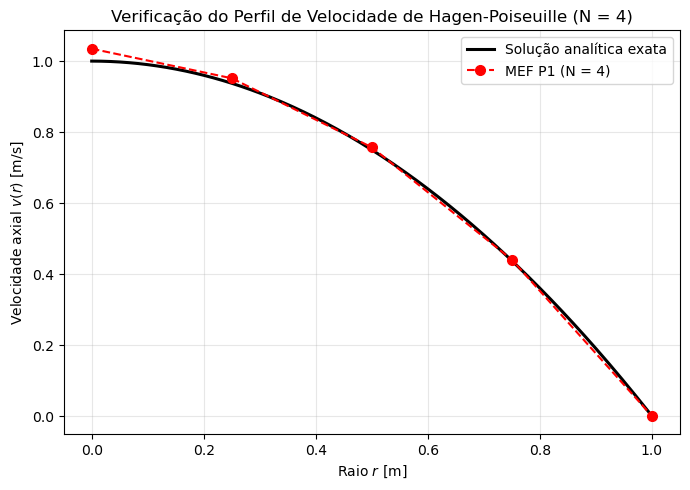

In [20]:
# ============================================================
# Verificação da solução numérica (N = 4, elemento P1)
# ============================================================

# 1. Função para calcular a solução analítica exata
def v_exato_func(r_pts, a_val=a, G_v=G_val, eta_v=eta_val):
    return (G_v / (4.0 * eta_v)) * (a_val**2 - r_pts**2)

# 2. Extração e ordenação das coordenadas dos graus de liberdade (como na Aula 3)
r_dofs = V.tabulate_dof_coordinates()[:, 0]
v_num = vh.x.array.real

ordem = np.argsort(r_dofs)
r_dofs = r_dofs[ordem]
v_num = v_num[ordem]

# Solução exata avaliada nos mesmos nós da malha
v_ex_dofs = v_exato_func(r_dofs)
erro_abs_nodal = np.abs(v_num - v_ex_dofs)

# 3. Tabela comparativa nos nós
print(f"{'Nó':>4} | {'r [m]':>10} | {'v_h (MEF) [m/s]':>16} | {'v_exato [m/s]':>16} | {'Erro Absoluto':>14}")
print("-" * 72)
for i in range(len(r_dofs)):
    print(f"{i:4d} | {r_dofs[i]:10.4f} | {v_num[i]:16.6f} | {v_ex_dofs[i]:16.6f} | {erro_abs_nodal[i]:14.6e}")

# 4. Medidas quantitativas de erro (Erro máximo nodal e Erro L2)
erro_max_nodal = np.max(erro_abs_nodal)

x_ufl = ufl.SpatialCoordinate(dominio)
v_exata_ufl = (G_val / (4.0 * eta_val)) * (a**2 - x_ufl[0]**2)
form_erro_L2 = fem.form((vh - v_exata_ufl)**2 * ufl.dx)
erro_L2 = np.sqrt(dominio.comm.allreduce(fem.assemble_scalar(form_erro_L2), op=MPI.SUM))

print("-" * 72)
print(f"Erro máximo nos nós (norma inf): {erro_max_nodal:.6e} m/s")
print(f"Erro global na norma L2        : {erro_L2:.6e}")

# 5. Gráfico comparativo
r_fino = np.linspace(0.0, a, 300)
v_fino = v_exato_func(r_fino)

plt.figure(figsize=(7, 5))
plt.plot(r_fino, v_fino, "k-", linewidth=2.2, label="Solução analítica exata")
plt.plot(r_dofs, v_num, "ro--", linewidth=1.5, markersize=7, label=f"MEF P1 (N = {N})")
plt.xlabel(r"Raio $r$ [m]")
plt.ylabel(r"Velocidade axial $v(r)$ [m/s]")
plt.title(f"Verificação do Perfil de Velocidade de Hagen-Poiseuille (N = {N})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig1_verificacao_N4.png", dpi=300)
plt.show()

## 14. Estudo de malha com $P_1$

Resolva para

$$N=2,\;4,\;8,\;16,\;32.$$

Construa uma tabela de erros e discuta:

1. **Há convergência?**  
   Sim. Conforme refinamos a malha aumentando $N$ de $2$ até $32$ (reduzindo o tamanho do elemento $h = a/N$), tanto o erro máximo nos nós quanto o erro global na norma $L^2$ diminuem monotonicamente em direção a zero.

2. **Como o erro varia com o refinamento?**  
   Sempre que dobramos o número de elementos $N$ (reduzindo $h$ pela metade), o erro na norma $L^2$ — e também o erro máximo nodal — cai por um fator próximo de $4$ ($2^2 = 4$). Isso comprova numericamente a **convergência quadrática** ($\text{Erro} \propto h^2$, ordem $p = 2$) característica dos elementos lineares $P_1$.

3. **Por que um único $P_1$ não reproduz exatamente o perfil?**  
   Porque uma função em $P_1$ é linear em cada elemento ($v_h(r) = c_0 + c_1 r$, derivada segunda nula), enquanto o perfil exato de Hagen–Poiseuille é uma parábola ($v_{\rm exato}(r) = C_1 - C_2 r^2$, derivada segunda constante e não nula). Uma única reta não consegue curvar-se para acompanhar uma parábola.

4. **O que diferencia este caso do Couette?**  
   No escoamento de Couette plano puro (sem gradiente de pressão, $G = 0$), a solução exata da equação diferencial é uma função linear (reta). Como uma reta pertence ao espaço $P_1$, até mesmo uma malha com $N = 1$ elemento $P_1$ já fornece erro zero. No escoamento de Hagen–Poiseuille, o gradiente de pressão $G \neq 0$ atua como termo fonte e gera um perfil quadrático que não pertence ao espaço $P_1$.

   N |     h [m] |   DOFs |  Erro Máx Nodal |         Erro L2 | Fator Queda L2
------------------------------------------------------------------------------
   2 |   0.50000 |      3 |    1.111111e-01 |    3.795167e-02 |       ---     
   4 |   0.25000 |      5 |    3.492063e-02 |    1.044136e-02 |           3.63x
   8 |   0.12500 |      9 |    1.053021e-02 |    2.731015e-03 |           3.82x
  16 |   0.06250 |     17 |    3.083504e-03 |    6.979357e-04 |           3.91x
  32 |   0.03125 |     33 |    8.836730e-04 |    1.763876e-04 |           3.96x


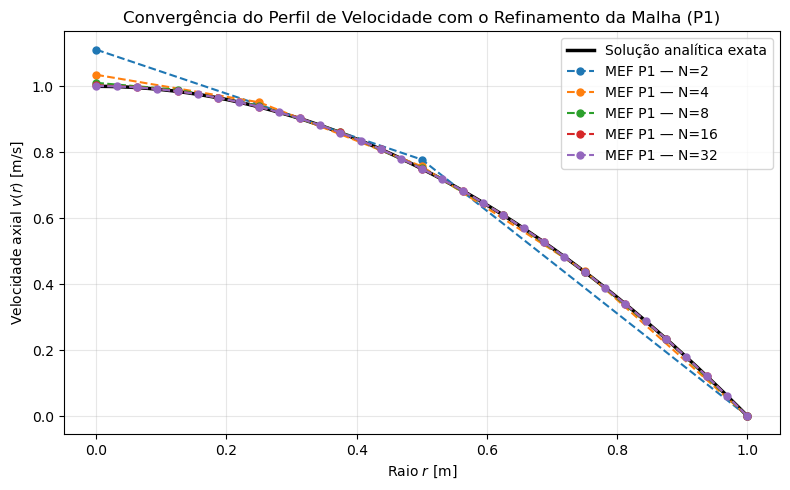

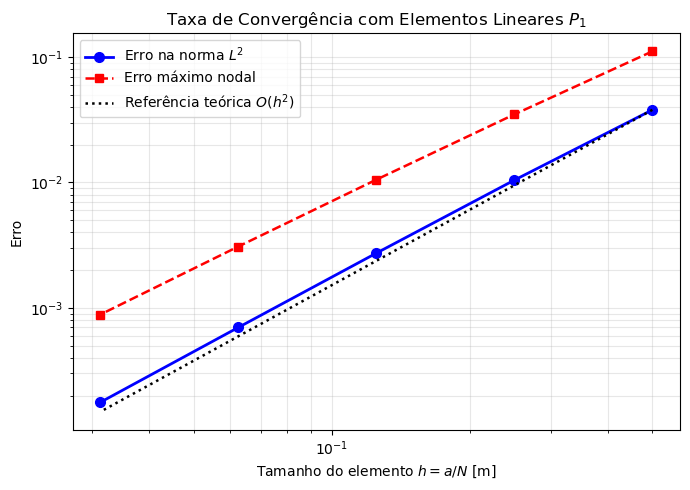

In [21]:
# ============================================================
# Funções auxiliares para resolver o problema e medir erros
# (Seguindo a mesma estrutura de resolver_poisson da Aula 3)
# ============================================================

def resolver_hagen_poiseuille(N_elem, grau=1, a_val=a, G_v=G_val, eta_v=eta_val):
    """
    Resolve o escoamento de Hagen-Poiseuille em [0, a_val]
    com N_elem elementos e polinômios de Lagrange de ordem 'grau'.
    """
    # 1. Malha 1D no intervalo [0, a_val]
    dom = mesh.create_interval(MPI.COMM_WORLD, N_elem, [0.0, a_val])

    # 2. Espaço de elementos finitos (P1 se grau=1, P2 se grau=2)
    V_esp = fem.functionspace(dom, ("Lagrange", grau))

    # 3. Funções tentativa e teste
    v_trial = ufl.TrialFunction(V_esp)
    w_test = ufl.TestFunction(V_esp)

    # 4. Coordenada radial r e parâmetros físicos
    x_coord = ufl.SpatialCoordinate(dom)
    r_coord = x_coord[0]
    eta_c = fem.Constant(dom, PETSc.ScalarType(eta_v))
    G_c = fem.Constant(dom, PETSc.ScalarType(G_v))

    # 5. Formas variacionais
    a_ufl = eta_c * r_coord * ufl.inner(ufl.grad(v_trial), ufl.grad(w_test)) * ufl.dx
    L_ufl = G_c * r_coord * w_test * ufl.dx

    # 6. Condição de contorno de Dirichlet na parede r = a_val: v(a_val) = 0
    fdim_local = dom.topology.dim - 1
    facets_parede = mesh.locate_entities_boundary(
        dom, fdim_local, lambda x: np.isclose(x[0], a_val)
    )
    dofs_p = fem.locate_dofs_topological(V_esp, fdim_local, facets_parede)
    bc_p = fem.dirichletbc(PETSc.ScalarType(0.0), dofs_p, V_esp)

    # 7. Montagem e solução do sistema linear
    prob = LinearProblem(
        a_ufl,
        L_ufl,
        bcs=[bc_p],
        petsc_options_prefix=f"hp_P{grau}_N{N_elem}_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"}
    )
    vh_sol = prob.solve()

    return dom, V_esp, vh_sol


def calcular_erros(dom, V_esp, vh_sol, a_val=a, G_v=G_val, eta_v=eta_val):
    """
    Calcula o erro máximo nos graus de liberdade e o erro na norma L2.
    """
    # Erro máximo nos nós (graus de liberdade)
    coords_r = V_esp.tabulate_dof_coordinates()[:, 0]
    valores_v = vh_sol.x.array.real
    valores_exatos = (G_v / (4.0 * eta_v)) * (a_val**2 - coords_r**2)
    erro_nodal_max = np.max(np.abs(valores_v - valores_exatos))

    # Erro na norma L2 (como na Aula 3, Seção 8.1)
    x_coord = ufl.SpatialCoordinate(dom)
    v_ex_ufl = (G_v / (4.0 * eta_v)) * (a_val**2 - x_coord[0]**2)
    erro_form = fem.form((vh_sol - v_ex_ufl)**2 * ufl.dx)
    erro_local = fem.assemble_scalar(erro_form)
    erro_L2_val = np.sqrt(dom.comm.allreduce(erro_local, op=MPI.SUM))

    return erro_nodal_max, erro_L2_val


# ============================================================
# Execução do estudo de convergência de malha para P1
# ============================================================
Ns = [2, 4, 8, 16, 32]
resultados_P1 = []
solucoes_P1 = {}

for N_atual in Ns:
    dom_N, V_N, vh_N = resolver_hagen_poiseuille(N_atual, grau=1)
    solucoes_P1[N_atual] = (dom_N, V_N, vh_N)

    h_atual = a / N_atual
    ndofs_atual = V_N.dofmap.index_map.size_global
    erro_max, erro_l2 = calcular_erros(dom_N, V_N, vh_N)

    resultados_P1.append((N_atual, h_atual, ndofs_atual, erro_max, erro_l2))

# Exibição da tabela de convergência
print(f"{'N':>4} | {'h [m]':>9} | {'DOFs':>6} | {'Erro Máx Nodal':>15} | {'Erro L2':>15} | {'Fator Queda L2':>14}")
print("-" * 78)

for idx, (N_i, h_i, ndof_i, emax_i, el2_i) in enumerate(resultados_P1):
    if idx == 0:
        fator_str = "      ---     "
    else:
        el2_anterior = resultados_P1[idx - 1][4]
        fator = el2_anterior / el2_i
        fator_str = f"{fator:14.2f}x"
    print(f"{N_i:4d} | {h_i:9.5f} | {ndof_i:6d} | {emax_i:15.6e} | {el2_i:15.6e} | {fator_str}")

# ============================================================
# Gráfico 1: Comparação dos perfis para diferentes malhas P1
# ============================================================
r_fino = np.linspace(0.0, a, 300)
v_fino = v_exato_func(r_fino)

plt.figure(figsize=(8, 5))
plt.plot(r_fino, v_fino, "k-", linewidth=2.5, label="Solução analítica exata")

for N_atual in Ns:
    dom_N, V_N, vh_N = solucoes_P1[N_atual]
    coords = V_N.tabulate_dof_coordinates()[:, 0]
    vals = vh_N.x.array.real
    ordem = np.argsort(coords)
    plt.plot(coords[ordem], vals[ordem], "o--", markersize=5, label=f"MEF P1 — N={N_atual}")

plt.xlabel(r"Raio $r$ [m]")
plt.ylabel(r"Velocidade axial $v(r)$ [m/s]")
plt.title("Convergência do Perfil de Velocidade com o Refinamento da Malha (P1)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig2_perfis_malha_P1.png", dpi=300)
plt.show()

# ============================================================
# Gráfico 2: Curva de convergência do erro (escala log-log)
# ============================================================
hs = np.array([item[1] for item in resultados_P1])
erros_max_arr = np.array([item[3] for item in resultados_P1])
erros_l2_arr = np.array([item[4] for item in resultados_P1])

# Reta de referência O(h^2)
ref_h2 = erros_l2_arr[0] * (hs / hs[0])**2

plt.figure(figsize=(7, 5))
plt.loglog(hs, erros_l2_arr, "bo-", linewidth=2, markersize=7, label=r"Erro na norma $L^2$")
plt.loglog(hs, erros_max_arr, "rs--", linewidth=1.8, markersize=6, label="Erro máximo nodal")
plt.loglog(hs, ref_h2, "k:", linewidth=1.8, label=r"Referência teórica $O(h^2)$")
plt.xlabel(r"Tamanho do elemento $h = a/N$ [m]")
plt.ylabel("Erro")
plt.title(r"Taxa de Convergência com Elementos Lineares $P_1$")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig3_convergencia_P1.png", dpi=300)
plt.show()

## 15. Comparação $P_1\times P_2$

Repita parte do estudo com elementos de Lagrange $P_2$.

Como

$$v(r)=C_1-C_2r^2,$$

investigue:

$$\boxed{\text{qual é a relação entre a ordem da solução e a ordem do elemento finito?}}$$

### Discussão Teórica e Evidência Numérica
- A solução analítica de Hagen–Poiseuille, $v_{\rm exato}(r) = \frac{G}{4\eta}(a^2 - r^2) = C_1 - C_2 r^2$, é um **polinômio quadrático (grau $p = 2$)**.
- Quando utilizamos elementos finitos de Lagrange $P_1$ (grau $k = 1 < 2$), o espaço de aproximação $V_h$ contém apenas funções lineares por partes ($v_{\rm exato} \notin V_h$), gerando um erro de discretização que diminui com $O(h^2)$.
- Por outro lado, quando utilizamos elementos de Lagrange $P_2$ (grau $k = 2$), as funções de base em cada elemento são polinômios quadráticos. Portanto, **a solução exata pertence exatamente ao espaço de elementos finitos ($v_{\rm exato} \in V_h$)**.
- Como resultado, para **qualquer** malha com elementos $P_2$ (inclusive com apenas $N = 2$ elementos), o Método dos Elementos Finitos reproduz a parábola exata a menos do erro de arredondamento de máquina em ponto flutuante ($\sim 10^{-16}$).

   N |  DOFs P1 |   Erro L2 (P1) |  DOFs P2 |   Erro L2 (P2) |  Erro Máx Nodal (P2)
----------------------------------------------------------------------------------
   2 |        3 |   3.795167e-02 |        5 |   2.175294e-16 |         6.661338e-16
   4 |        5 |   1.044136e-02 |        9 |   6.006876e-16 |         8.881784e-16
   8 |        9 |   2.731015e-03 |       17 |   2.439375e-15 |         3.552714e-15
  16 |       17 |   6.979357e-04 |       33 |   7.802820e-15 |         1.199041e-14
  32 |       33 |   1.763876e-04 |       65 |   1.283761e-14 |         2.131628e-14


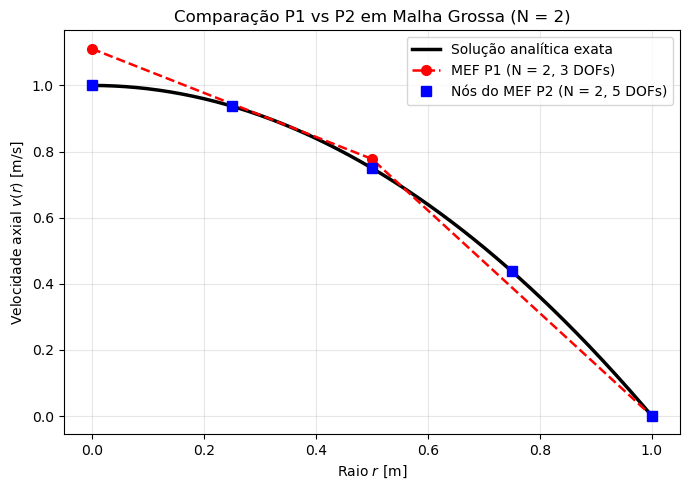

In [22]:
# ============================================================
# Comparação direta entre Elementos Lineares (P1) e Quadráticos (P2)
# ============================================================
Ns_comp = [2, 4, 8, 16, 32]
resultados_P2 = []
solucoes_P2 = {}

for N_atual in Ns_comp:
    dom_2, V_2, vh_2 = resolver_hagen_poiseuille(N_atual, grau=2)
    solucoes_P2[N_atual] = (dom_2, V_2, vh_2)

    h_atual = a / N_atual
    ndofs_2 = V_2.dofmap.index_map.size_global
    erro_max_2, erro_l2_2 = calcular_erros(dom_2, V_2, vh_2)

    resultados_P2.append((N_atual, h_atual, ndofs_2, erro_max_2, erro_l2_2))

# Tabela comparativa lado a lado: P1 vs P2
print(f"{'N':>4} | {'DOFs P1':>8} | {'Erro L2 (P1)':>14} | {'DOFs P2':>8} | {'Erro L2 (P2)':>14} | {'Erro Máx Nodal (P2)':>20}")
print("-" * 82)

for i in range(len(Ns_comp)):
    N_i, _, dof_p1, _, l2_p1 = resultados_P1[i]
    _, _, dof_p2, max_p2, l2_p2 = resultados_P2[i]
    print(f"{N_i:4d} | {dof_p1:8d} | {l2_p1:14.6e} | {dof_p2:8d} | {l2_p2:14.6e} | {max_p2:20.6e}")

# ============================================================
# Gráfico comparativo P1 vs P2 para malha grossa (N = 2)
# ============================================================
N_exemplo = 2
_, V_p1_ex, vh_p1_ex = solucoes_P1[N_exemplo]
_, V_p2_ex, vh_p2_ex = solucoes_P2[N_exemplo]

# Coordenadas e valores de P1 (N = 2)
r_p1 = V_p1_ex.tabulate_dof_coordinates()[:, 0]
v_p1 = vh_p1_ex.x.array.real
ord_p1 = np.argsort(r_p1)
r_p1, v_p1 = r_p1[ord_p1], v_p1[ord_p1]

# Coordenadas e valores dos graus de liberdade de P2 (N = 2)
r_p2 = V_p2_ex.tabulate_dof_coordinates()[:, 0]
v_p2 = vh_p2_ex.x.array.real
ord_p2 = np.argsort(r_p2)
r_p2, v_p2 = r_p2[ord_p2], v_p2[ord_p2]

plt.figure(figsize=(7, 5))
plt.plot(r_fino, v_fino, "k-", linewidth=2.5, label="Solução analítica exata")
plt.plot(r_p1, v_p1, "ro--", linewidth=1.8, markersize=7, label=f"MEF P1 (N = {N_exemplo}, 3 DOFs)")
plt.plot(r_p2, v_p2, "bs", markersize=7, label=f"Nós do MEF P2 (N = {N_exemplo}, 5 DOFs)")
plt.xlabel(r"Raio $r$ [m]")
plt.ylabel(r"Velocidade axial $v(r)$ [m/s]")
plt.title(f"Comparação P1 vs P2 em Malha Grossa (N = {N_exemplo})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig4_comparacao_P1_P2.png", dpi=300)
plt.show()

## 16. Vazão numérica

Como

$$dA=2\pi r\,dr,$$

calcule

$$\boxed{Q_h=2\pi\int_0^a v_h(r)r\,dr}$$

e compare com

$$Q_{\rm exato}=\frac{\pi a^4G}{8\eta}.$$

### Origem geométrica do fator $2\pi r$
Em um escoamento axisimétrico, todos os pontos situados a uma mesma distância radial $r$ do eixo possuem a mesma velocidade axial $v(r)$. Para integrar a velocidade na seção transversal circular do tubo, dividimos o círculo em **anéis concêntricos infinitesimais** de raio $r$ e espessura $dr$. Como o comprimento (perímetro) da circunferência de raio $r$ é $2\pi r$, a área de cada anel infinitesimal é $dA = 2\pi r\,dr$, resultando na integral $Q = \int_0^a v(r)\,2\pi r\,dr$.

Vazão analítica exata (Q_exato) = 1.57079633 m^3/s

   N |   Q_h (P1) [m^3/s] |  Erro Rel. P1 [%] |   Q_h (P2) [m^3/s] |  Erro Rel. P2 [%]
------------------------------------------------------------------------------------
   2 |         1.51261869 |           3.7037% |         1.57079633 |       0.0000e+00%
   4 |         1.55500525 |           1.0053% |         1.57079633 |       9.8951e-14%
   8 |         1.56674879 |           0.2577% |         1.57079633 |       3.2512e-13%
  16 |         1.56977683 |           0.0649% |         1.57079633 |       8.6228e-13%
  32 |         1.57054089 |           0.0163% |         1.57079633 |       1.6256e-12%


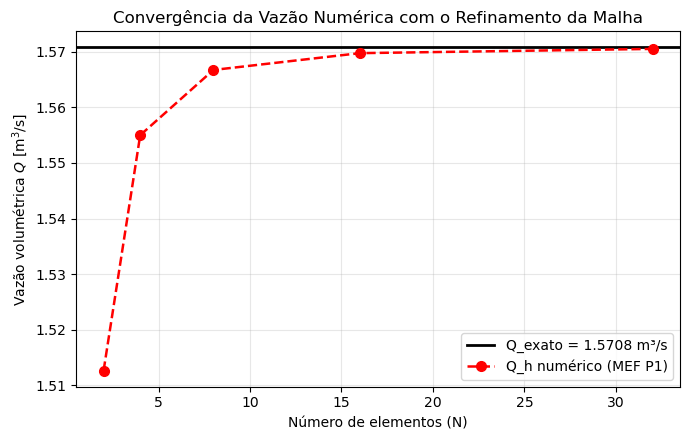

In [23]:
# ============================================================
# Cálculo da vazão volumétrica numérica Q_h e comparação
# ============================================================

def calcular_vazao(dom, vh_sol):
    """
    Calcula a vazão volumétrica numérica Q_h = 2 * pi * integral(vh * r dr)
    usando fem.form e fem.assemble_scalar (mesmo padrão da Aula 3).
    """
    x_coord = ufl.SpatialCoordinate(dom)
    r_coord = x_coord[0]

    forma_vazao = fem.form(2.0 * np.pi * vh_sol * r_coord * ufl.dx)
    vazao_local = fem.assemble_scalar(forma_vazao)
    vazao_global = dom.comm.allreduce(vazao_local, op=MPI.SUM)

    return vazao_global


Q_exato = (np.pi * (a ** 4) * G_val) / (8.0 * eta_val)
print(f"Vazão analítica exata (Q_exato) = {Q_exato:.8f} m^3/s\n")

print(f"{'N':>4} | {'Q_h (P1) [m^3/s]':>18} | {'Erro Rel. P1 [%]':>17} | {'Q_h (P2) [m^3/s]':>18} | {'Erro Rel. P2 [%]':>17}")
print("-" * 84)

vazoes_P1 = []
erros_rel_Q_P1 = []

for N_atual in Ns:
    dom_1, _, vh_1 = solucoes_P1[N_atual]
    dom_2, _, vh_2 = solucoes_P2[N_atual]

    Q_h_1 = calcular_vazao(dom_1, vh_1)
    Q_h_2 = calcular_vazao(dom_2, vh_2)

    erro_rel_1 = abs(Q_h_1 - Q_exato) / Q_exato * 100.0
    erro_rel_2 = abs(Q_h_2 - Q_exato) / Q_exato * 100.0

    vazoes_P1.append(Q_h_1)
    erros_rel_Q_P1.append(erro_rel_1)

    print(f"{N_atual:4d} | {Q_h_1:18.8f} | {erro_rel_1:16.4f}% | {Q_h_2:18.8f} | {erro_rel_2:16.4e}%")

# Gráfico da convergência da vazão numérica
plt.figure(figsize=(7, 4.5))
plt.axhline(Q_exato, color="k", linestyle="-", linewidth=2, label=f"Q_exato = {Q_exato:.4f} m³/s")
plt.plot(Ns, vazoes_P1, "ro--", linewidth=1.8, markersize=7, label="Q_h numérico (MEF P1)")
plt.xlabel("Número de elementos (N)")
plt.ylabel(r"Vazão volumétrica $Q$ [m$^3$/s]")
plt.title("Convergência da Vazão Numérica com o Refinamento da Malha")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/fig5_convergencia_vazao.png", dpi=300)
plt.show()

## 17. Investigação física

Investigue numericamente

$$Q\propto(p_1-p_2),\qquad Q\propto\frac1\eta,\qquad Q\propto a^4.$$

### Experimento obrigatório — Aumento de 10% no raio ($a_{\rm novo} = 1{,}10\,a$)

1. **Previsão teórica antes de executar:**  
   Pela Lei de Hagen–Poiseuille, $Q = \frac{\pi a^4 G}{8\eta}$. Mantendo $G$ e $\eta$ constantes, a vazão é proporcional à quarta potência do raio ($Q \propto a^4$).  
   Se aumentarmos o raio em $10\%$, temos $a_{\rm novo} = 1{,}10\,a$, logo:
   $$\frac{Q_{\rm novo}}{Q_{\rm original}} = \left(\frac{1{,}10\,a}{a}\right)^4 = (1{,}10)^4 = 1{,}4641.$$
   Portanto, a previsão teórica é um aumento percentual de ** exatamente $+46{,}41\%$** na vazão volumétrica!

2. **Explicação física do resultado:**  
   Por que um aumento de apenas $10\%$ no raio produz quase $50\%$ a mais de vazão? Porque o raio atua duplamente no escoamento laminar interno:
   - Primeiro, a **área da seção transversal** cresce com o quadrado do raio ($A = \pi a^2 \implies (1{,}10)^2 = +21\%$ de área para o fluido passar);
   - Segundo, como as paredes ficam mais afastadas do centro, o efeito de freio viscoso diminui e a **velocidade máxima (e média)** do fluido também cresce com o quadrado do raio ($v_{\max} = \frac{G a^2}{4\eta} \implies (1{,}10)^2 = +21\%$ na velocidade média).
   - O produto $Q = \bar{v} \cdot A$ combina os dois efeitos: $a^2 \times a^2 = a^4$, resultando em $(1{,}10)^4 = 1{,}4641$ ($+46{,}41\%$). Essa fortíssima sensibilidade explica, por exemplo, na fisiologia cardiovascular, por que uma pequena vasoconstrição ou placa de ateroma que reduza o raio de uma artéria em apenas $10\%$ reduz o fluxo sanguíneo em cerca de $34\%$ ($0{,}9^4 = 0{,}6561$).

=== EXPERIMENTO OBRIGATÓRIO: +10% NO RAIO ===
Raio original (a)              = 1.0000 m  -> Q_h = 1.570796 m^3/s
Raio aumentado (a_novo = 1.1a) = 1.1000 m  -> Q_h = 2.299803 m^3/s
Razão numérica Q_novo / Q_orig = 1.464100 (Teórico: 1.10^4 = 1.464100)
Aumento percentual teórico     = +46.41%
Aumento percentual numérico    = +46.41%



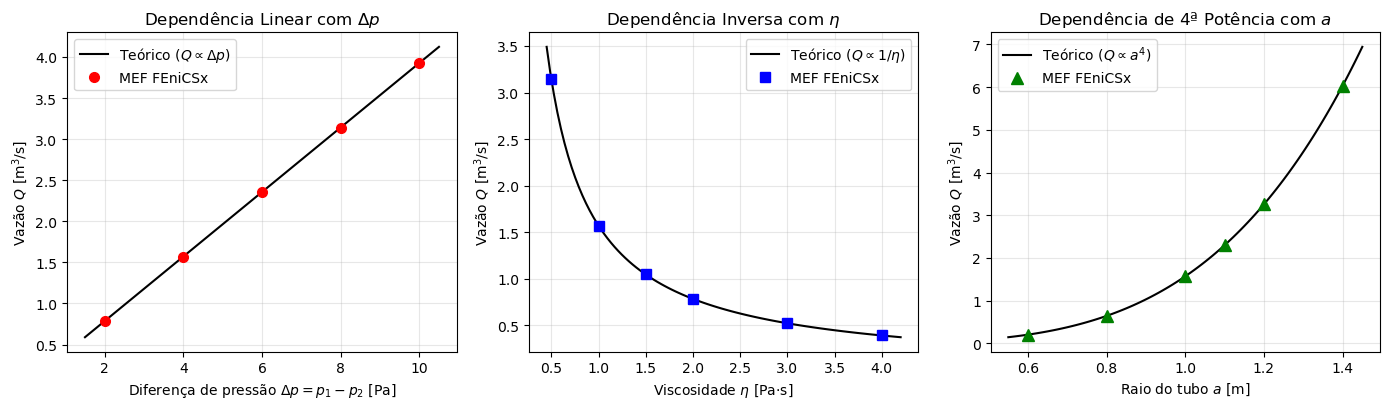

In [24]:
# ============================================================
# 1. Experimento obrigatório: aumento de 10% no raio (a_novo = 1.10 * a)
# ============================================================
a_novo = 1.10 * a
N_exp = 32  # Malha refinada

# Solução numérica com o raio original (a = 1.0 m) e com o novo raio (a_novo = 1.10 m)
dom_orig, _, vh_orig = resolver_hagen_poiseuille(N_exp, grau=2, a_val=a, G_v=G_val, eta_v=eta_val)
dom_novo, _, vh_novo = resolver_hagen_poiseuille(N_exp, grau=2, a_val=a_novo, G_v=G_val, eta_v=eta_val)

Q_num_orig = calcular_vazao(dom_orig, vh_orig)
Q_num_novo = calcular_vazao(dom_novo, vh_novo)

variacao_teorica_pct = ((1.10 ** 4) - 1.0) * 100.0
variacao_numerica_pct = ((Q_num_novo - Q_num_orig) / Q_num_orig) * 100.0

print("=== EXPERIMENTO OBRIGATÓRIO: +10% NO RAIO ===")
print(f"Raio original (a)              = {a:.4f} m  -> Q_h = {Q_num_orig:.6f} m^3/s")
print(f"Raio aumentado (a_novo = 1.1a) = {a_novo:.4f} m  -> Q_h = {Q_num_novo:.6f} m^3/s")
print(f"Razão numérica Q_novo / Q_orig = {Q_num_novo / Q_num_orig:.6f} (Teórico: 1.10^4 = {1.10**4:.6f})")
print(f"Aumento percentual teórico     = +{variacao_teorica_pct:.2f}%")
print(f"Aumento percentual numérico    = +{variacao_numerica_pct:.2f}%\n")

# ============================================================
# 2. Estudo paramétrico: Q vs (p1 - p2), Q vs eta, Q vs a
# ============================================================
dp_lista = [2.0, 4.0, 6.0, 8.0, 10.0]
Q_dp_num = []
for dp in dp_lista:
    G_teste = dp / l
    d_t, _, v_t = resolver_hagen_poiseuille(16, grau=2, a_val=a, G_v=G_teste, eta_v=eta_val)
    Q_dp_num.append(calcular_vazao(d_t, v_t))

eta_lista = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
Q_eta_num = []
for eta_t in eta_lista:
    d_t, _, v_t = resolver_hagen_poiseuille(16, grau=2, a_val=a, G_v=G_val, eta_v=eta_t)
    Q_eta_num.append(calcular_vazao(d_t, v_t))

a_lista = [0.6, 0.8, 1.0, 1.1, 1.2, 1.4]
Q_a_num = []
for a_t in a_lista:
    d_t, _, v_t = resolver_hagen_poiseuille(16, grau=2, a_val=a_t, G_v=G_val, eta_v=eta_val)
    Q_a_num.append(calcular_vazao(d_t, v_t))

# Curvas teóricas contínuas para comparação
dp_fino = np.linspace(1.5, 10.5, 100)
eta_fino = np.linspace(0.45, 4.2, 100)
a_fino_param = np.linspace(0.55, 1.45, 100)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Painel 1: Q vs Delta p
axes[0].plot(dp_fino, (np.pi * a**4 * (dp_fino / l)) / (8 * eta_val), "k-", label="Teórico ($Q \\propto \\Delta p$)")
axes[0].plot(dp_lista, Q_dp_num, "ro", markersize=7, label="MEF FEniCSx")
axes[0].set_xlabel(r"Diferença de pressão $\Delta p = p_1 - p_2$ [Pa]")
axes[0].set_ylabel(r"Vazão $Q$ [m$^3$/s]")
axes[0].set_title(r"Dependência Linear com $\Delta p$")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Painel 2: Q vs viscosidade eta
axes[1].plot(eta_fino, (np.pi * a**4 * G_val) / (8 * eta_fino), "k-", label=r"Teórico ($Q \propto 1/\eta$)")
axes[1].plot(eta_lista, Q_eta_num, "bs", markersize=7, label="MEF FEniCSx")
axes[1].set_xlabel(r"Viscosidade $\eta$ [Pa$\cdot$s]")
axes[1].set_ylabel(r"Vazão $Q$ [m$^3$/s]")
axes[1].set_title(r"Dependência Inversa com $\eta$")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Painel 3: Q vs raio a
axes[2].plot(a_fino_param, (np.pi * (a_fino_param**4) * G_val) / (8 * eta_val), "k-", label=r"Teórico ($Q \propto a^4$)")
axes[2].plot(a_lista, Q_a_num, "g^", markersize=8, label="MEF FEniCSx")
axes[2].set_xlabel(r"Raio do tubo $a$ [m]")
axes[2].set_ylabel(r"Vazão $Q$ [m$^3$/s]")
axes[2].set_title(r"Dependência de 4ª Potência com $a$")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig("figuras/fig6_investigacao_fisica.png", dpi=300)
plt.show()

## 18. Artigo — formato SBC

O relatório do Projeto 1 deverá ser escrito no formato de **artigo**, utilizando o:

**SBC Conferences Template — updated `sbc-template.sty` v2017**

Template no Overleaf:  
https://www.overleaf.com/latex/templates/sbc-conferences-template/blbxwjwzdngr

A edição pode ser feita diretamente no **Overleaf** ou em outro ambiente LaTeX compatível. A entrega final do artigo deverá ser em **PDF**.

### Estrutura sugerida

1. **Título**
2. **Autores e identificação institucional**
3. **Resumo e Abstract**
4. **Introdução**
5. **Escoamento de Hagen–Poiseuille**
   - modelo físico;
   - hipóteses;
   - solução analítica.
6. **Formulação pelo Método dos Elementos Finitos**
   - forma forte;
   - forma fraca;
   - discretização.
7. **Implementação no FEniCSx**
8. **Resultados e Discussão**
   - verificação com a solução analítica;
   - estudo de convergência da malha;
   - comparação entre $P_1$ e $P_2$;
   - cálculo da vazão;
   - investigação dos parâmetros físicos.
9. **Conclusões**
10. **Referências bibliográficas**

### Extensão

O artigo deverá ter **6 a 8 páginas**, incluindo figuras, tabelas e referências.

O **código completo não deverá ser colocado no artigo**. Trechos curtos podem ser utilizados quando forem importantes para a discussão. A implementação completa será entregue separadamente no notebook Jupyter.

O artigo deve comunicar os resultados científicos; o notebook deve garantir a **reprodutibilidade computacional**.

## 19. Conclusões

Com base nos resultados teóricos e numéricos obtidos neste notebook, destacam-se as seguintes conclusões técnicas para o artigo:

1. **Adequação do MEF e da formulação variacional axisimétrica:**  
   A redução do problema tridimensional no cilindro para o domínio radial unidimensional $[0, a]$, incorporando o fator geométrico $r$ na forma fraca ($\int_0^a \eta r v' w'\,dr = \int_0^a G r w\,dr$), permitiu tratar a condição de simetria no eixo ($v'(0) = 0$) de forma natural (Neumann homogênea), exigindo condição essencial de Dirichlet apenas na parede ($v(a) = 0$).

2. **Efeito do refinamento da malha com elementos $P_1$:**  
   Como as funções de forma $P_1$ são lineares por partes e o perfil de Hagen–Poiseuille é quadrático, malhas grossas apresentam erro de interpolação visível. Entretanto, o estudo de convergência ($N = 2, 4, 8, 16, 32$) confirmou que, ao dobrar $N$ ($h \to h/2$), o erro na norma $L^2$ reduz-se por um fator de $4$, verificando a taxa teórica de segunda ordem $\mathcal{O}(h^2)$.

3. **Diferenças entre $P_1$ e $P_2$:**  
   Ao empregar elementos quadráticos de Lagrange ($P_2$), o espaço discreto $V_h$ passa a conter polinômios de 2º grau. Como a solução exata $v_{\rm exato}(r) = C_1 - C_2 r^2$ é quadrática ($v_{\rm exato} \in P_2$), o MEF com $P_2$ atinge erro da ordem da precisão de máquina ($\sim 10^{-16}$) já para $N = 2$ elementos.

4. **Concordância da vazão numérica com a Lei de Hagen–Poiseuille:**  
   A integração numérica de $Q_h = 2\pi \int_0^a v_h(r) r\,dr$ converge rapidamente para $Q_{\rm exato} = \frac{\pi a^4 G}{8\eta}$ nos elementos $P_1$ (com erro relativo caindo um fator $4$ a cada refinamento) e coincide exatamente com o valor analítico nos elementos $P_2$.

5. **Efeito dos parâmetros físicos:**  
   As simulações confirmaram a proporcionalidade direta com $\Delta p$, inversa com $\eta$ e de quarta potência com o raio $a$. Em particular, o experimento de acréscimo de $+10\%$ no raio comprovou numericamente o aumento de $+46{,}41\%$ na vazão ($1{,}10^4 = 1{,}4641$).

6. **Principais cuidados de implementação identificados:**  
   Os dois pontos mais críticos na implementação em FEniCSx foram: (i) não esquecer de multiplicar tanto a forma bilinear quanto a forma linear pela coordenada radial `r = x[0]`; e (ii) localizar exclusivamente a fronteira $r = a$ com `np.isclose(x[0], a)` para não bloquear indevidamente o nó central $r = 0$.

## 20. Entrega e reprodutibilidade

Cada grupo deverá entregar:

1. **artigo em PDF**, produzido com o template SBC indicado na Seção 18;
2. **notebook Jupyter (`.ipynb`) executável**.

O notebook deverá:
- executar da primeira à última célula;
- conter todos os parâmetros necessários;
- reproduzir as tabelas e figuras utilizadas no artigo;
- apresentar comentários suficientes para relacionar código e formulação matemática;
- não depender de variáveis criadas por execução fora de ordem.

### Antes de entregar

**Reinicie o kernel e execute `Run All`.**

Se o notebook não reproduzir os resultados após esse procedimento, ele não está computacionalmente reprodutível.

## 21. Organização sugerida — 3 semanas

### Semana 1 — Modelagem e formulação
Dedução física, forma forte, forma fraca e condições de contorno.

### Semana 2 — Implementação e verificação
FEniCSx, comparação analítica, estudo inicial de malha e vazão.

### Semana 3 — Experimentos e artigo
$P_1/P_2$, parâmetros físicos, gráficos, tabelas, discussão, redação e revisão.

## Uso de Inteligência Artificial — Relato de Verificação Crítica

Em conformidade com as diretrizes do projeto sobre o uso consciente e tecnicamente verificável de ferramentas de IA, registramos abaixo a análise crítica de uma interação realizada durante o desenvolvimento:

1. **Pergunta / problema apresentado à IA:**  
   Como adaptar a implementação do problema de Poisson da Aula 3 (em que $u=0$ era aplicado em todo o contorno com `lambda x: np.full(x.shape[1], True)`) para o problema radial 1D de Hagen–Poiseuille em $r \in [0, a]$, garantindo a condição de não deslizamento em $r = a$ e a simetria no eixo $r = 0$, bem como o cálculo da integral da vazão $Q_h$ no FEniCSx.

2. **Orientação / solução proposta pela IA:**  
   A ferramenta orientou a: (i) substituir o marcador booleano geral por `lambda x: np.isclose(x[0], a)` em `mesh.locate_entities_boundary` para aplicar Dirichlet somente na parede $r = a$; (ii) deixar o nó $r = 0$ livre porque o termo de fronteira $-\left[\eta r v'(r) w(r)\right]_0^a$ se anula naturalmente em $r = 0$; e (iii) calcular a vazão usando `fem.form(2 * np.pi * vh * x[0] * ufl.dx)` com `fem.assemble_scalar`.

3. **Como o grupo verificou a resposta:**  
   A verificação foi realizada em três frentes:  
   - **Analítica:** Conferimos a integração por partes manualmente e confirmamos que o termo de fronteira em $r=0$ se anula sem impor restrição sobre $w(0)$;
   - **Numérica no perfil de velocidade:** Comparamos $v_h(r)$ com $v_{\rm exato}(r) = \frac{G}{4\eta}(a^2 - r^2)$, verificando que em $r = 0$ a velocidade numérica converge para $v_{\max} = 1{,}0\text{ m/s}$ (em $P_1$ com taxa $\mathcal{O}(h^2)$ e em $P_2$ com erro de $10^{-16}$);
   - **Numérica na vazão:** Comparamos $Q_h$ com $Q_{\rm exato} = \frac{\pi a^4 G}{8\eta} = \frac{\pi}{2} \approx 1{,}570796\text{ m}^3/\text{s}$ e validamos o experimento de $+10\%$ no raio ($Q_{\rm novo}/Q_{\rm orig} = 1{,}4641$).

4. **Avaliação da correção:**  
   A solução estava matematicamente e computacionalmente correta, compatível com a versão do DOLFINx (`0.11.0`) utilizada nas aulas.

5. **O que a verificação acrescentou à compreensão do problema:**  
   Consolidou a distinção prática entre **condição de contorno essencial (Dirichlet)** — que deve ser imposta no espaço de funções via `dirichletbc` em $r = a$ — e **condição de contorno natural (Neumann/simetria)** — que emerge automaticamente da forma fraca em $r = 0$, além de demonstrar por que a escolha de elementos $P_2$ elimina o erro de discretização para perfis parabólicos.